In [1]:
import sys
sys.path.append('..')

In [2]:
from src import utils
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
import copy

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/1957256453.py:15: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/1957256453.py:43: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('coolwarm')


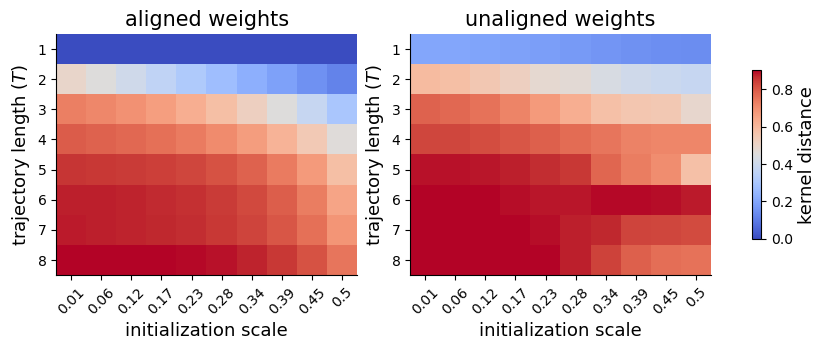

In [ ]:
# Fig. 5: trained on constant task dynamics (s_t=1)
data_path = Path('../data/richlazy_search_constant_aligned_scale0to0.5/')
rich_lazy_search_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

na_data_path = Path('../data/richlazy_search_constant_unaligned_scale0to0.5/')
na_rich_lazy_search_tape = utils.load_dict(na_data_path / 'rich_lazy_search_tape.pkl')

fig = plt.figure(figsize=(9,3), layout='constrained')
axes = fig.subplots(nrows=1, ncols=2)
for ax in axes.flat: 
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
fig.tight_layout()

vmin_a = np.min(rich_lazy_search_tape.NTK_distance_mean[np.where(np.isnan(rich_lazy_search_tape.NTK_distance_mean) == False)])
vmax_a = np.max(rich_lazy_search_tape.NTK_distance_mean[np.where(np.isnan(rich_lazy_search_tape.NTK_distance_mean) == False)])

vmin_na = np.min(rich_lazy_search_tape.NTK_distance_mean[np.where(np.isnan(na_rich_lazy_search_tape.NTK_distance_mean) == False)])
vmax_na = np.max(rich_lazy_search_tape.NTK_distance_mean[np.where(np.isnan(na_rich_lazy_search_tape.NTK_distance_mean) == False)])

vmin = min(vmin_a, vmin_na)
vmax = max(vmax_a, vmax_na)

axes[0].set_yticks(range(8), range(1,9))
axes[0].imshow(rich_lazy_search_tape.NTK_distance_mean, cmap='coolwarm',vmin=vmin, vmax=vmax)
axes[0].set_title('aligned weights', fontsize=15)
axes[0].set_xlabel('initialization scale', fontsize=13)
axes[0].set_ylabel('trajectory length ($T$)', fontsize=13)
axes[0].tick_params(axis='both', which='major', labelsize=10)
axes[0].set_xticks(range(10), np.round(np.linspace(0.02, 1.0, 10)/2,2),rotation=45)

axes[1].set_yticks(range(8), range(1,9))
axes[1].imshow(na_rich_lazy_search_tape.NTK_distance_mean, cmap='coolwarm',vmin=vmin, vmax=vmax)
axes[1].set_title('unaligned weights', fontsize=15)
axes[1].set_xlabel('initialization scale', fontsize=13)
axes[1].set_ylabel('trajectory length ($T$)', fontsize=13)
axes[1].tick_params(axis='both', which='major', labelsize=10)
axes[1].set_xticks(range(10), np.round(np.linspace(0.02, 1.0, 10)/2,2), rotation=45)

colormap = plt.cm.get_cmap('coolwarm')
normalizer = matplotlib.colors.Normalize(vmin,vmax)
im = matplotlib.cm.ScalarMappable(norm=normalizer, cmap=colormap)
cb = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7,drawedges=False)
cb.set_label(label=r'kernel distance',size=13)
# fig.savefig('paper_figs/rich_and_lazy_phase_multiseed.pdf', dpi=300, transparent=True, bbox_inches='tight')

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/1982820768.py:14: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/1982820768.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('coolwarm')


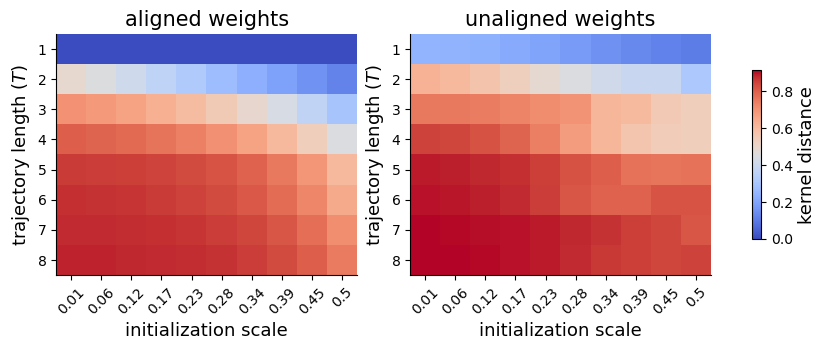

In [4]:
# Fig. A4: trained on rotation matrix

data_path = Path('../data/richlazy_search_rotation_v2_aligned/')
a_rotations_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

na_data_path = Path('../data/richlazy_search_rotation_v2_unaligned/')
na_rotations_tape = utils.load_dict(na_data_path / 'rich_lazy_search_tape.pkl')

fig = plt.figure(figsize=(9,3), layout='constrained')
axes = fig.subplots(nrows=1, ncols=2)
for ax in axes.flat: #axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
fig.tight_layout()

# Shared color range for both heatmaps
vmin_a = np.min(a_rotations_tape.NTK_distance_mean[np.where(np.isnan(a_rotations_tape.NTK_distance_mean) == False)])
vmax_a = np.max(a_rotations_tape.NTK_distance_mean[np.where(np.isnan(a_rotations_tape.NTK_distance_mean) == False)])

vmin_na = np.min(na_rotations_tape.NTK_distance_mean[np.where(np.isnan(na_rotations_tape.NTK_distance_mean) == False)])
vmax_na = np.max(na_rotations_tape.NTK_distance_mean[np.where(np.isnan(na_rotations_tape.NTK_distance_mean) == False)])

vmin = min(vmin_a, vmin_na)
vmax = max(vmax_a, vmax_na)

axes[0].set_yticks(range(8), range(1,9))
axes[0].imshow(a_rotations_tape.NTK_distance_mean, cmap='coolwarm',vmin=vmin, vmax=vmax)
axes[0].set_title('aligned weights', fontsize=15)
axes[0].set_xlabel('initialization scale', fontsize=13)
axes[0].set_ylabel('trajectory length ($T$)', fontsize=13)
axes[0].tick_params(axis='both', which='major', labelsize=10)
axes[0].set_xticks(range(10), np.round(np.linspace(0.02, 1.0, 10)/2,2),rotation=45)

axes[1].set_yticks(range(8), range(1,9))
axes[1].imshow(np.nanmean(na_rotations_tape.NTK_distance,axis=-1), cmap='coolwarm',vmin=vmin, vmax=vmax)
axes[1].set_title('unaligned weights', fontsize=15)
axes[1].set_xlabel('initialization scale', fontsize=13)
axes[1].set_ylabel('trajectory length ($T$)', fontsize=13)
axes[1].tick_params(axis='both', which='major', labelsize=10)
axes[1].set_xticks(range(10), np.round(np.linspace(0.02, 1.0, 10)/2,2), rotation=45)

colormap = plt.cm.get_cmap('coolwarm')
normalizer = matplotlib.colors.Normalize(vmin,vmax)
im = matplotlib.cm.ScalarMappable(norm=normalizer, cmap=colormap)
cb = fig.colorbar(im, ax=axes.ravel().tolist(), shrink=0.7,drawedges=False)
cb.set_label(label=r'kernel distance',size=13)
# Adjust layout for better spacing and compactness
# plt.tight_layout(pad=1)  # Reduce padding between subplots
plt.show()
# fig.savefig('paper_figs/rich_and_lazy_rotation.pdf', dpi=300, transparent=True, bbox_inches='tight')

In [9]:
data_path = Path('../data/richlazy_search_infinite_width_unaligned_firstry(interrupted)/')
inf_width_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

all_NTK = copy.deepcopy(inf_width_tape.NTK_distance_mean)

# infinite width
data_path = Path('../data/richlazy_search_infinite_width_unaligned_secondtry/')
inf_width_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

all_NTK[4] = inf_width_tape.NTK_distance_mean[0]
all_NTK[5] = inf_width_tape.NTK_distance_mean[1]
all_NTK[6] = inf_width_tape.NTK_distance_mean[2]


# infinite width
data_path = Path('../data/richlazy_search_infinite_width_unaligned_thirdtry/')
inf_width_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

all_NTK[6,-1] = inf_width_tape.NTK_distance_mean

# infinite width
data_path = Path('../data/richlazy_search_infinite_width_unaligned/')
inf_width_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

all_NTK[7] = inf_width_tape.NTK_distance_mean

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/2742058507.py:19: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  all_NTK[6,-1] = inf_width_tape.NTK_distance_mean


/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/533442124.py:14: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/533442124.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('coolwarm')


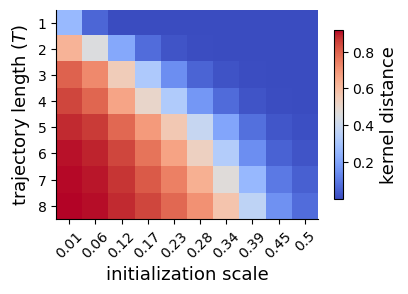

In [10]:
# Fig A5: larger width (N=300), constant task dynamics, unaligned weights

data_path = Path('../data/richlazy_search_infinite_width_unaligned/')
inf_width_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

fig = plt.figure(figsize=(4,3), layout='constrained')
ax = fig.subplots(nrows=1, ncols=1)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
fig.tight_layout()

vmin = np.min(all_NTK[np.where(np.isnan(all_NTK) == False)])
vmax = np.max(all_NTK[np.where(np.isnan(all_NTK) == False)])

ax.set_yticks(range(8), range(1,9))
ax.imshow(all_NTK, cmap='coolwarm',vmin=vmin, vmax=vmax)
ax.set_xlabel('initialization scale', fontsize=13)
ax.set_ylabel('trajectory length ($T$)', fontsize=13)
ax.tick_params(axis='both', which='major', labelsize=10)

ax.set_xticks(range(10), np.round(np.linspace(0.02, 1.0, 10)/2,2),rotation=45)

colormap = plt.cm.get_cmap('coolwarm')
normalizer = matplotlib.colors.Normalize(vmin,vmax)
im = matplotlib.cm.ScalarMappable(norm=normalizer, cmap=colormap)
cb = fig.colorbar(im, ax=ax, shrink=0.7,drawedges=False)
cb.set_label(label=r'kernel distance',size=13)
# fig.savefig('paper_figs/rich_and_lazy_infinite_width.pdf', dpi=300, transparent=True, bbox_inches='tight')

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/2160633744.py:14: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/2160633744.py:35: RuntimeWarning: Mean of empty slice
  axes[1].imshow(np.nanmean(na_rich_lazy_search_tape.NTK_distance,axis=-1), cmap='coolwarm',vmin=vmin,vmax=vmax)
/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/2160633744.py:43: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('coolwarm')


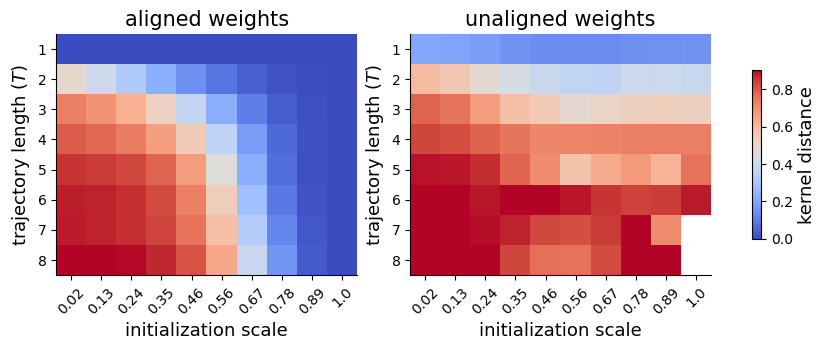

In [6]:
# Fig A6: larger initialization scale

data_path = Path('../data/richlazy_search_constant_aligned/')
rich_lazy_search_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

na_data_path = Path('../data/richlazy_search_constant_unaligned/')
na_rich_lazy_search_tape = utils.load_dict(na_data_path / 'rich_lazy_search_tape.pkl')

fig = plt.figure(figsize=(9,3), layout='constrained')
axes = fig.subplots(nrows=1, ncols=2)
for ax in axes.flat: 
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
fig.tight_layout()

vmin_a = np.min(rich_lazy_search_tape.NTK_distance_mean[np.where(np.isnan(rich_lazy_search_tape.NTK_distance_mean) == False)])
vmax_a = np.max(rich_lazy_search_tape.NTK_distance_mean[np.where(np.isnan(rich_lazy_search_tape.NTK_distance_mean) == False)])

vmin_na = np.min(rich_lazy_search_tape.NTK_distance_mean[np.where(np.isnan(na_rich_lazy_search_tape.NTK_distance_mean) == False)])
vmax_na = np.max(rich_lazy_search_tape.NTK_distance_mean[np.where(np.isnan(na_rich_lazy_search_tape.NTK_distance_mean) == False)])

vmin = min(vmin_a, vmin_na)
vmax = max(vmax_a, vmax_na)

axes[0].set_yticks(range(8), range(1,9))
axes[0].imshow(rich_lazy_search_tape.NTK_distance_mean, cmap='coolwarm',vmin=vmin, vmax=vmax)
axes[0].set_title('aligned weights', fontsize=15)
axes[0].set_xlabel('initialization scale', fontsize=13)
axes[0].set_ylabel('trajectory length ($T$)', fontsize=13)
axes[0].tick_params(axis='both', which='major', labelsize=10)
axes[0].set_xticks(range(10), np.round(np.linspace(0.02, 1.0, 10),2),rotation=45)

axes[1].set_yticks(range(8), range(1,9))
axes[1].imshow(np.nanmean(na_rich_lazy_search_tape.NTK_distance,axis=-1), cmap='coolwarm',vmin=vmin,vmax=vmax)
axes[1].set_title('unaligned weights', fontsize=15)
axes[1].set_xlabel('initialization scale', fontsize=13)
axes[1].set_ylabel('trajectory length ($T$)', fontsize=13)
axes[1].tick_params(axis='both', which='major', labelsize=10)
axes[1].set_xticks(range(10), np.round(np.linspace(0.02, 1.0, 10),2), rotation=45)

colormap = plt.cm.get_cmap('coolwarm')
normalizer = matplotlib.colors.Normalize(vmin,vmax)
im = matplotlib.cm.ScalarMappable(norm=normalizer, cmap=colormap)
cb = fig.colorbar(im, ax=axes.ravel().tolist(), label=r'kernel distance', shrink=0.7,drawedges=False)
cb.set_label(label=r'kernel distance',size=13)
# fig.savefig('paper_figs/rich_and_lazy_phase_largeinit_both.pdf', dpi=300, transparent=True, bbox_inches='tight')

/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/3639243092.py:17: UserWarning: The figure layout has changed to tight
  fig.tight_layout()
/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/3639243092.py:38: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('coolwarm')
/var/folders/88/p8znsc4j3wj6nq2cj7m_l4xr0000gn/T/ipykernel_20491/3639243092.py:90: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colormap = plt.cm.get_cmap('coolwarm')


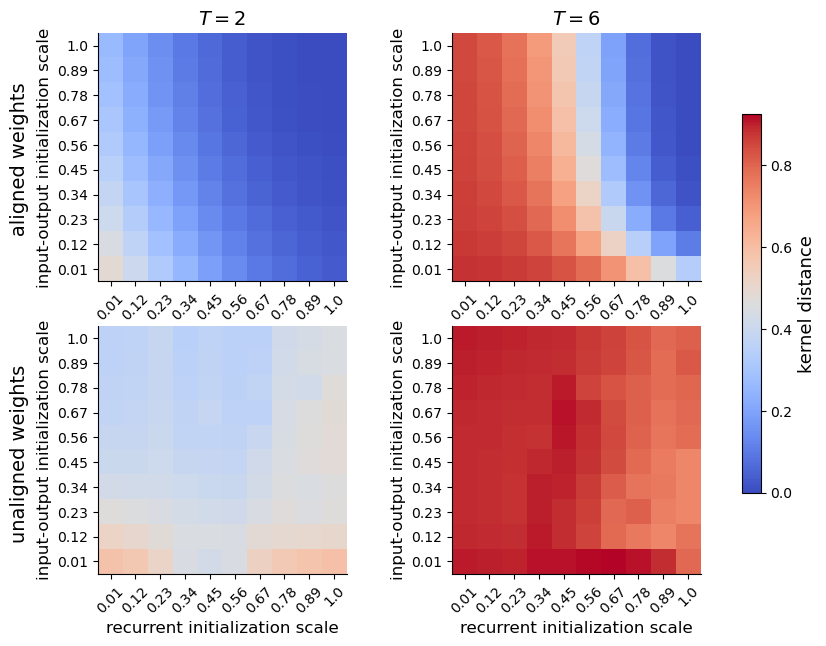

In [7]:
# Fig A7: recurrent vs. input-output initialization

# independent modes aligned & unaligned
data_path = Path('../data/richlazy_search_independent_modes_init_aligned/')
indep_modes_a_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

# # unaligned
data_path = Path('../data/richlazy_search_independent_modes_init_unaligned/')
indep_modes_na_tape = utils.load_dict(data_path / 'rich_lazy_search_tape.pkl')

fig = plt.figure(figsize=(9,6), layout='constrained')
axes = fig.subplots(nrows=2, ncols=2)
for ax in axes.flat:
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    
fig.tight_layout()

vmin_a = np.min(indep_modes_a_tape.NTK_distance_mean[np.where(np.isnan(indep_modes_a_tape.NTK_distance_mean) == False)])
vmax_a = np.max(indep_modes_a_tape.NTK_distance_mean[np.where(np.isnan(indep_modes_a_tape.NTK_distance_mean) == False)])

vmin_na = np.min(indep_modes_na_tape.NTK_distance_mean[np.where(np.isnan(indep_modes_na_tape.NTK_distance_mean) == False)])
vmax_na = np.max(indep_modes_na_tape.NTK_distance_mean[np.where(np.isnan(indep_modes_na_tape.NTK_distance_mean) == False)])

vmin = min(vmin_a, vmin_na)
vmax = max(vmax_a, vmax_na)

vmin_aT2 = np.min(indep_modes_a_tape.NTK_distance_mean[1][np.where(np.isnan(indep_modes_a_tape.NTK_distance_mean[1]) == False)])
vmax_aT2 = np.max(indep_modes_a_tape.NTK_distance_mean[1][np.where(np.isnan(indep_modes_a_tape.NTK_distance_mean[1]) == False)])
axes.flat[0].imshow(np.flipud(indep_modes_a_tape.NTK_distance_mean[1]), cmap='coolwarm',vmin=vmin, vmax=vmax) #vmin=vmin_aT2, vmax=vmax_aT2)
axes.flat[0].set_title(r'$T=2$', fontsize=14)
axes.flat[0].set_xlabel('recurrent initialization scale', fontsize=12)
axes.flat[0].set_ylabel('input-output initialization scale', fontsize=12)
axes.flat[0].tick_params(axis='both', which='major', labelsize=10)
axes.flat[0].set_xticks(range(10), np.linspace(0.01, 1.0, 10),rotation=45)
axes.flat[0].set_yticks(range(10), np.flip(np.linspace(0.01, 1.0, 10)))
colormap = plt.cm.get_cmap('coolwarm')

vmin_aT6 = np.min(indep_modes_a_tape.NTK_distance_mean[2][np.where(np.isnan(indep_modes_a_tape.NTK_distance_mean[2]) == False)])
vmax_aT6 = np.max(indep_modes_a_tape.NTK_distance_mean[2][np.where(np.isnan(indep_modes_a_tape.NTK_distance_mean[2]) == False)])
axes.flat[1].imshow(np.flipud(indep_modes_a_tape.NTK_distance_mean[2]), cmap='coolwarm',vmin=vmin, vmax=vmax) #vmin=vmin_aT6, vmax=vmax_aT6)
axes.flat[1].set_title(r'$T=6$', fontsize=14)
axes.flat[1].set_xlabel('recurrent initialization scale', fontsize=12)
axes.flat[1].set_ylabel('input-output initialization scale', fontsize=12)
axes.flat[1].tick_params(axis='both', which='major', labelsize=10)
axes.flat[1].set_xticks(range(10), np.linspace(0.01, 1.0, 10),rotation=45)
axes.flat[1].set_yticks(range(10), np.flip(np.linspace(0.01, 1.0, 10)))

vmin_naT2 = np.min(indep_modes_na_tape.NTK_distance_mean[0][np.where(np.isnan(indep_modes_na_tape.NTK_distance_mean[0]) == False)])
vmax_naT2 = np.max(indep_modes_na_tape.NTK_distance_mean[0][np.where(np.isnan(indep_modes_na_tape.NTK_distance_mean[0]) == False)])
axes.flat[2].imshow(np.flipud(np.nanmean(indep_modes_na_tape.NTK_distance[0],axis=-1)), cmap='coolwarm',vmin=vmin, vmax=vmax) #vmin=vmin_naT2, vmax=vmax_naT2)
axes.flat[2].set_xlabel('recurrent initialization scale', fontsize=12)
axes.flat[2].set_ylabel('input-output initialization scale', fontsize=12)
axes.flat[2].tick_params(axis='both', which='major', labelsize=10)
axes.flat[2].set_xticks(range(10), np.linspace(0.01, 1.0, 10), rotation=45)
axes.flat[2].set_yticks(range(10), np.flip(np.linspace(0.01, 1.0, 10))) #np.linspace(0.01, 1.0, 10))

vmin_naT6 = np.min(indep_modes_na_tape.NTK_distance_mean[1][np.where(np.isnan(indep_modes_na_tape.NTK_distance_mean[1]) == False)])
vmax_naT6 = np.max(indep_modes_na_tape.NTK_distance_mean[1][np.where(np.isnan(indep_modes_na_tape.NTK_distance_mean[1]) == False)])
axes.flat[3].imshow(np.flipud(np.nanmean(indep_modes_na_tape.NTK_distance[1],axis=-1)), cmap='coolwarm',vmin=vmin, vmax=vmax) #vmin=vmin_naT6, vmax=vmax_naT6)
axes.flat[3].set_xlabel('recurrent initialization scale', fontsize=12)
axes.flat[3].set_ylabel('input-output initialization scale', fontsize=12)
axes.flat[3].tick_params(axis='both', which='major', labelsize=10)
axes.flat[3].set_xticks(range(10), np.linspace(0.01, 1.0, 10), rotation=45)
axes.flat[3].set_yticks(range(10), np.flip(np.linspace(0.01, 1.0, 10)))

colormap = plt.cm.get_cmap('coolwarm')
normalizer = matplotlib.colors.Normalize(vmin,vmax)
im = matplotlib.cm.ScalarMappable(norm=normalizer, cmap=colormap)
cb = fig.colorbar(im, ax=axes.ravel().tolist(), label=r'kernel distance', shrink=0.7,drawedges=False)
cb.set_label(label=r'kernel distance',size=13)
fig.supylabel('unaligned weights                     aligned weights',fontsize=14)

# fig.savefig('paper_figs/rich_and_lazy_independent_modes_both.pdf', dpi=300, transparent=True, bbox_inches='tight')